# Проект: Анализ резюме из HeadHunter

Файлы `dst-3.0_16_1_hh_database.csv` [https://drive.google.com/file/d/158cZ0XKhqfQge8UO4tMLa0dX-BrSDs5I/view?usp=sharing](https://drive.google.com/file/d/158cZ0XKhqfQge8UO4tMLa0dX-BrSDs5I/view?usp=sharing) и `ExchangeRates.csv` [https://drive.google.com/file/d/1qCXsAouTm2JNPmlzBJgGTidTbngiJM2d/view?usp=sharing](https://drive.google.com/file/d/1qCXsAouTm2JNPmlzBJgGTidTbngiJM2d/view?usp=sharing)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [2]:
data = pd.read_csv('dst-3.0_16_1_hh_database.csv', sep=';')

2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [3]:
display(data.head())

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
0,"Мужчина , 39 лет , родился 27 ноября 1979",29000 руб.,Системный администратор,"Советск (Калининградская область) , не готов к...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, ва...",Опыт работы 16 лет 10 месяцев Август 2010 — п...,"МАОУ ""СОШ № 1 г.Немана""",Системный администратор,Неоконченное высшее образование 2000 Балтийск...,16.04.2019 15:59,Имеется собственный автомобиль
1,"Мужчина , 60 лет , родился 20 марта 1959",40000 руб.,Технический писатель,"Королев , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, уд...",Опыт работы 19 лет 5 месяцев Январь 2000 — по...,Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель",Высшее образование 1981 Военно-космическая ак...,12.04.2019 08:42,Не указано
2,"Женщина , 36 лет , родилась 12 августа 1982",20000 руб.,Оператор,"Тверь , не готова к переезду , не готова к ком...",полная занятость,полный день,Опыт работы 10 лет 3 месяца Октябрь 2004 — Де...,ПАО Сбербанк,Кассир-операционист,Среднее специальное образование 2002 Профессио...,16.04.2019 08:35,Не указано
3,"Мужчина , 38 лет , родился 25 июня 1980",100000 руб.,Веб-разработчик (HTML / CSS / JS / PHP / базы ...,"Саратов , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, удаленная работа",Опыт работы 18 лет 9 месяцев Август 2017 — Ап...,OpenSoft,Инженер-программист,Высшее образование 2002 Саратовский государст...,08.04.2019 14:23,Не указано
4,"Женщина , 26 лет , родилась 3 марта 1993",140000 руб.,Региональный менеджер по продажам,"Москва , не готова к переезду , готова к коман...",полная занятость,полный день,Опыт работы 5 лет 7 месяцев Региональный мене...,Мармелад,Менеджер по продажам,Высшее образование 2015 Кгу Психологии и педаг...,22.04.2019 10:32,Не указано


3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Пол, возраст                     44744 non-null  object
 1   ЗП                               44744 non-null  object
 2   Ищет работу на должность:        44744 non-null  object
 3   Город, переезд, командировки     44744 non-null  object
 4   Занятость                        44744 non-null  object
 5   График                           44744 non-null  object
 6   Опыт работы                      44576 non-null  object
 7   Последнее/нынешнее место работы  44743 non-null  object
 8   Последняя/нынешняя должность     44742 non-null  object
 9   Образование и ВУЗ                44744 non-null  object
 10  Обновление резюме                44744 non-null  object
 11  Авто                             44744 non-null  object
dtypes: object(12)
memory usage: 4.1+

4. Обратите внимание на информацию о числе непустых значений.

In [5]:
print(data.isnull().sum())

Пол, возраст                         0
ЗП                                   0
Ищет работу на должность:            0
Город, переезд, командировки         0
Занятость                            0
График                               0
Опыт работы                        168
Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Образование и ВУЗ                    0
Обновление резюме                    0
Авто                                 0
dtype: int64


5. Выведите основную статистическую информацию о столбцах.


In [6]:
display(data.describe())

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
count,44744,44744,44744,44744,44744,44744,44576,44743,44742,44744,44744,44744
unique,16003,690,14929,10063,38,47,44413,30214,16927,40148,18838,2
top,"Мужчина , 32 года , родился 17 сентября 1986",50000 руб.,Системный администратор,"Москва , не готов к переезду , не готов к кома...",полная занятость,полный день,Опыт работы 10 лет 8 месяцев Апрель 2018 — по...,Индивидуальное предпринимательство / частная п...,Системный администратор,Высшее образование 1987 Военный инженерный Кра...,07.05.2019 09:50,Не указано
freq,18,4064,3099,1261,30026,22727,3,935,2062,4,25,32268


# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [7]:
def get_education(value):
    words = value.split()
    if words[0] == 'Высшее':
        return 'высшее'
    if words[0] == 'Неоконченное':
        return 'неоконченное высшее'
    if words[1] == 'специальное':
        return 'среднее специальное'
    return 'среднее'


data['Образование'] = data['Образование и ВУЗ'].apply(get_education)
print(data['Образование'].unique())
data = data.drop(['Образование и ВУЗ'], axis=1)

['неоконченное высшее' 'высшее' 'среднее специальное' 'среднее']


2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '. 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [8]:
data['Пол'] = data['Пол, возраст'].apply(lambda value: value[0])
data['Возраст'] = data['Пол, возраст'].apply(lambda value: int(value.split(',')[1].split()[0]))

data = data.drop(['Пол, возраст'], axis=1)

3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование и удалите столбец **"Опыт работы"** из таблицы.


In [9]:
def get_experience(value):
    if type(value) != str or value == 'Не указано':
        return np.nan
    words = value.split()[2:6]
    months = 0
    for i in range(1, len(words)):
        if words[i] in ['год', 'года', 'лет']:
            months += int(words[i - 1]) * 12
        elif words[i] in ['месяц', 'месяца', 'месяцев']:
            months += int(words[i - 1])
    return months


data['Опыт работы (месяц)'] = data['Опыт работы'].apply(get_experience)
data = data.drop(['Опыт работы'], axis=1)

4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [10]:
million_cities = [
    'Новосибирск', 'Екатеринбург', 'Нижний Новгород', 'Казань',
    'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону', 'Уфа',
    'Красноярск', 'Пермь', 'Воронеж', 'Волгоград'
]


def get_city(value):
    city = value.split(' ,')[0]
    if city in ['Москва', 'Санкт-Петербург']:
        return city
    if city in million_cities:
        return 'город-миллионник'
    return 'другие'


def get_relocation(value):
    if 'не готов к переезду' in value or 'не готова к переезду' in value:
        return False
    return ('готов к переезду' in value or 'готова к переезду' in value
            or 'хочу переехать' in value)


def get_business_trips(value):
    if 'командировкам' not in value:
        return False
    if 'не готов к командировкам' in value or 'не готова к командировкам' in value:
        return False
    return True


data['Город'] = data['Город, переезд, командировки'].apply(get_city)
data['Готовность к переезду'] = data['Город, переезд, командировки'].apply(get_relocation)
data['Готовность к командировкам'] = data['Город, переезд, командировки'].apply(get_business_trips)

data = data.drop(['Город, переезд, командировки'], axis=1)

5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding : в каждом новом столбце хранится True или False.
Выполните данное преобразование для признаков "Занятость" и "График", после чего удалите их из таблицы

In [11]:
employment_types = [
    'полная занятость', 'частичная занятость', 'проектная работа',
    'волонтерство', 'стажировка'
]
schedule_types = [
    'полный день', 'сменный график', 'гибкий график',
    'удаленная работа', 'вахтовый метод'
]

for category in employment_types:
    data[category] = data['Занятость'].apply(lambda value: category in value.split(', '))
for category in schedule_types:
    data[category] = data['График'].apply(lambda value: category in value.split(', '))

data = data.drop(['Занятость', 'График'], axis=1)

6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.


| Валюта в резюме | ISO-код | Пропорция |
|---|---|---|
| грн. | UAH | 10 |
| USD | USD | 1 |
| EUR | EUR | 1 |
| бел.руб. | BYN | 1 |
| KGS | KGS | 10 |
| сум | UZS | 10000 |
| AZN | AZN | 1 |
| KZT | KZT | 100 |



Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После преобразования удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования: 
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [12]:
rates = pd.read_csv('ExchangeRates.csv')
rates = rates[['currency', 'date', 'proportion', 'close']].copy()
rates['date'] = rates['date'].apply(lambda value: value[:-2] + '20' + value[-2:])
rates['date'] = pd.to_datetime(rates['date'], dayfirst=True).dt.date
data['Обновление резюме'] = pd.to_datetime(
    data['Обновление резюме'], dayfirst=True
).dt.date

currency_names = {
    'руб.': 'RUB', 'грн.': 'UAH', 'USD': 'USD', 'EUR': 'EUR',
    'бел.руб.': 'BYN', 'KGS': 'KGS', 'сум': 'UZS', 'AZN': 'AZN', 'KZT': 'KZT'
}
data['Сумма'] = data['ЗП'].apply(lambda value: float(value.split()[0]))
data['Валюта'] = data['ЗП'].apply(lambda value: currency_names[value.split()[-1]])

data = data.merge(
    rates, how='left', left_on=['Обновление резюме', 'Валюта'],
    right_on=['date', 'currency']
)
data['close'] = data['close'].fillna(1)
data['proportion'] = data['proportion'].fillna(1)
data['ЗП (руб)'] = data['Сумма'] * data['close'] / data['proportion']

data = data.drop(['ЗП', 'Сумма', 'Валюта', 'currency', 'date', 'close', 'proportion'], axis=1)

# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

Мода возраста: 30
Минимальный возраст: 14
Максимальный возраст: 100


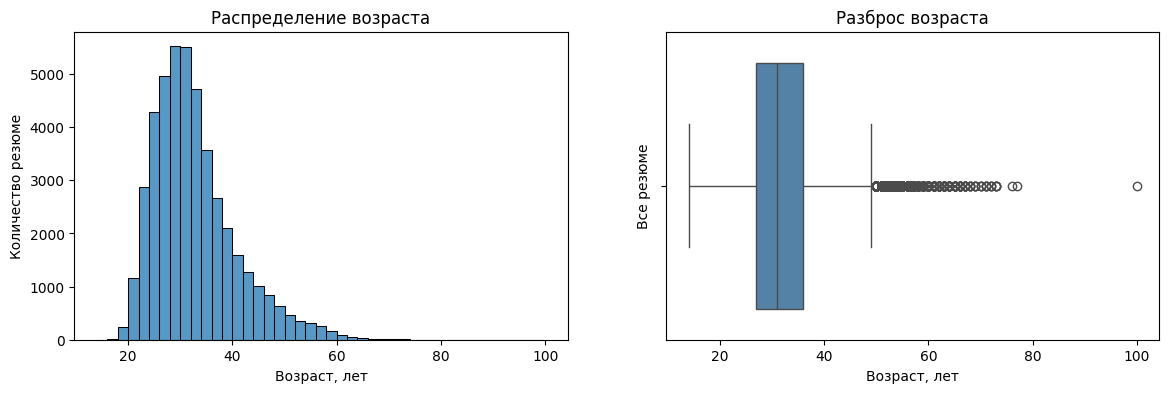

In [13]:
print('Мода возраста:', data['Возраст'].mode()[0])
print('Минимальный возраст:', data['Возраст'].min())
print('Максимальный возраст:', data['Возраст'].max())

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 4))
sns.histplot(data=data, x='Возраст', bins=43, ax=axes[0])
axes[0].set_title('Распределение возраста')
axes[0].set_xlabel('Возраст, лет')
axes[0].set_ylabel('Количество резюме')
sns.boxplot(data=data, x='Возраст', ax=axes[1], color='steelblue')
axes[1].set_title('Разброс возраста')
axes[1].set_xlabel('Возраст, лет')
axes[1].set_ylabel('Все резюме')
plt.show()

Мода возраста равна 30 годам, минимум составляет 14 лет, максимум 100 лет. Основная часть соискателей находится примерно в возрасте от 20 до 50 лет. Распределение имеет длинный правый хвост. Значение 100 лет выглядит подозрительно. Возраст старше 50 лет сам по себе не означает ошибку.

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

Мода опыта: 81.0
Минимальный опыт: 1.0
Максимальный опыт: 1188.0


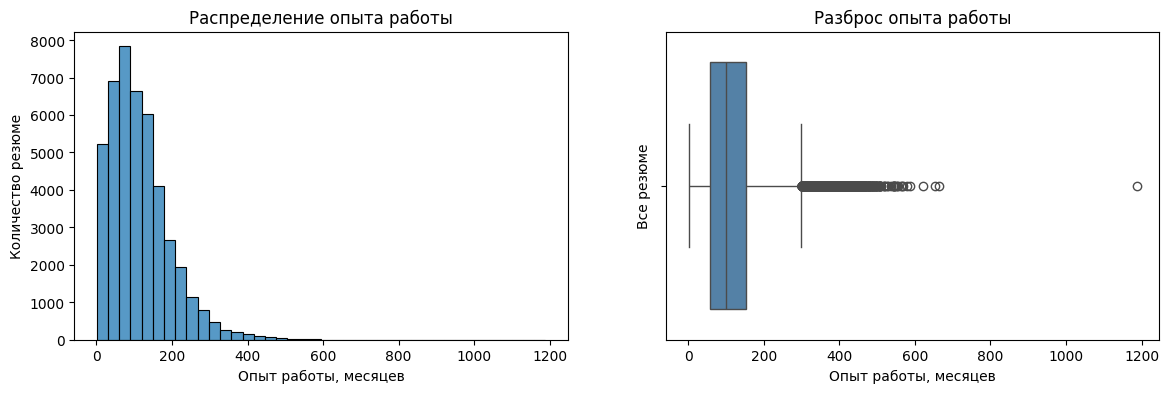

In [14]:
experience = data['Опыт работы (месяц)']
print('Мода опыта:', experience.mode()[0])
print('Минимальный опыт:', experience.min())
print('Максимальный опыт:', experience.max())

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 4))
sns.histplot(data=data, x='Опыт работы (месяц)', bins=40, ax=axes[0])
axes[0].set_title('Распределение опыта работы')
axes[0].set_xlabel('Опыт работы, месяцев')
axes[0].set_ylabel('Количество резюме')
sns.boxplot(data=data, x='Опыт работы (месяц)', ax=axes[1], color='steelblue')
axes[1].set_title('Разброс опыта работы')
axes[1].set_xlabel('Опыт работы, месяцев')
axes[1].set_ylabel('Все резюме')
plt.show()

Мода опыта равна 81 месяцу. Значения находятся в диапазоне от 1 до 1188 месяцев, при этом основная часть наблюдений не превышает примерно 300 месяцев. Распределение асимметрично вправо. Значение 1188 месяцев выглядит аномальным. Большие значения опыта нужно сопоставить с возрастом соискателей.

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака заработной платы? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


Минимальная зарплата: 1.0
Максимальная зарплата: 24304876.0


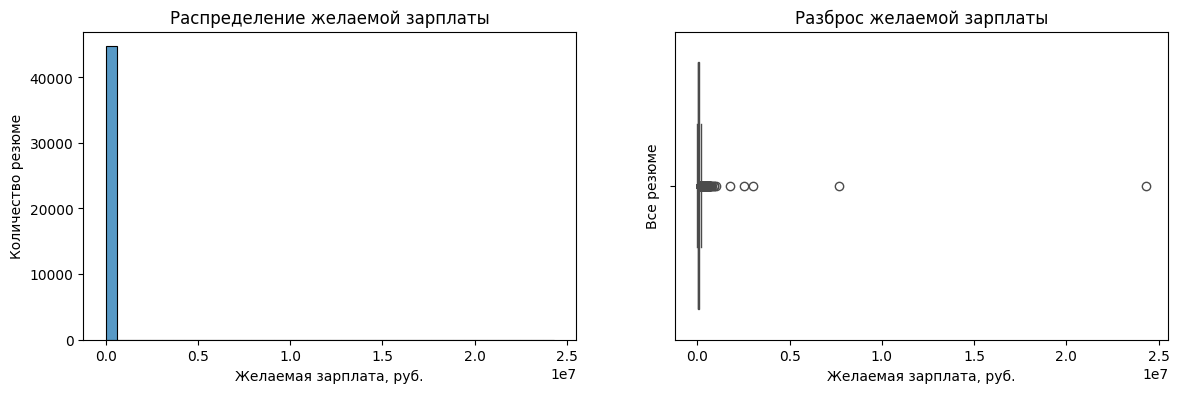

In [15]:
print('Минимальная зарплата:', data['ЗП (руб)'].min())
print('Максимальная зарплата:', data['ЗП (руб)'].max())

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 4))
sns.histplot(data=data, x='ЗП (руб)', bins=40, ax=axes[0])
axes[0].set_title('Распределение желаемой зарплаты')
axes[0].set_xlabel('Желаемая зарплата, руб.')
axes[0].set_ylabel('Количество резюме')
sns.boxplot(data=data, x='ЗП (руб)', color='steelblue', ax=axes[1])
axes[1].set_title('Разброс желаемой зарплаты')
axes[1].set_xlabel('Желаемая зарплата, руб.')
axes[1].set_ylabel('Все резюме')
plt.show()

Минимальная желаемая зарплата равна 1 рублю, максимальная составляет 24 304 876 рублей. Основная часть значений находится примерно между 20 и 100 тысячами рублей. Распределение имеет длинный правый хвост. Суммы около одного рубля и многомиллионные зарплаты выглядят подозрительно.

4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

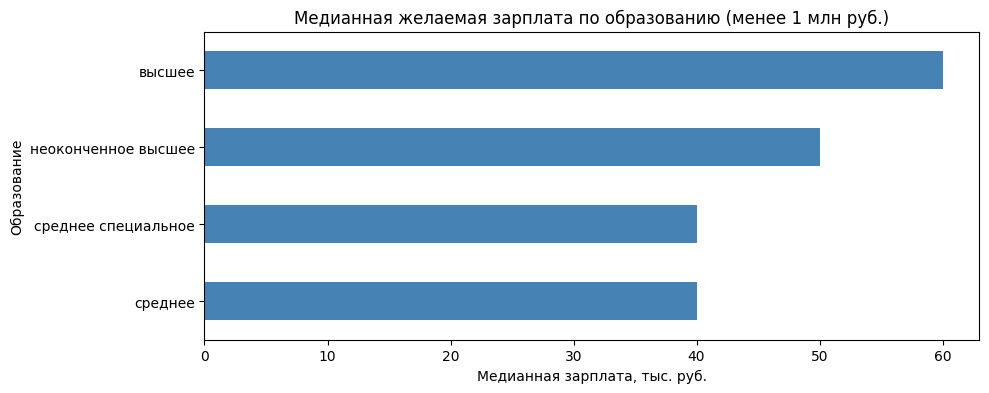

In [16]:
salary_under_million = data[data['ЗП (руб)'] < 1000000].copy()
education_salary = salary_under_million.groupby('Образование')['ЗП (руб)'].median().sort_values()

ax = (education_salary / 1000).plot(kind='barh', figsize=(10, 4), color='steelblue')
ax.set_title('Медианная желаемая зарплата по образованию (менее 1 млн руб.)')
ax.set_xlabel('Медианная зарплата, тыс. руб.')
ax.set_ylabel('Образование')
plt.show()

Самая высокая медианная желаемая зарплата у соискателей с высшим образованием: 60 тысяч рублей. При неоконченном высшем образовании она равна 50 тысячам, при среднем и среднем специальном по 40 тысяч рублей. Образование связано с зарплатными ожиданиями и может быть полезно для прогноза. Эти различия также могут зависеть от профессии, опыта и города. Речь идёт о желаемой, а не фактической оплате труда.

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

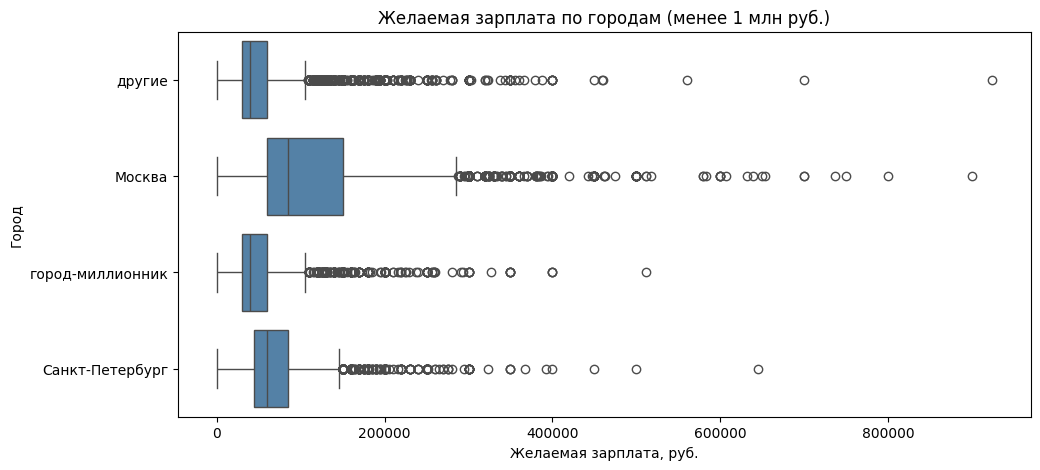

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=salary_under_million, x='ЗП (руб)', y='Город', color='steelblue', ax=ax)
ax.set_title('Желаемая зарплата по городам (менее 1 млн руб.)')
ax.set_xlabel('Желаемая зарплата, руб.')
ax.set_ylabel('Город')
plt.show()

Наибольшая медианная желаемая зарплата в Москве: 85 тысяч рублей, далее Санкт-Петербург с 60 тысячами, города-миллионники и другие города с 40 тысячами. В Москве шире разброс центральной части распределения. При этом наибольший полный размах с учётом крайних значений у категории «другие». Город полезен для прогноза, поскольку различаются как типичные зарплатные ожидания, так и их разброс.

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

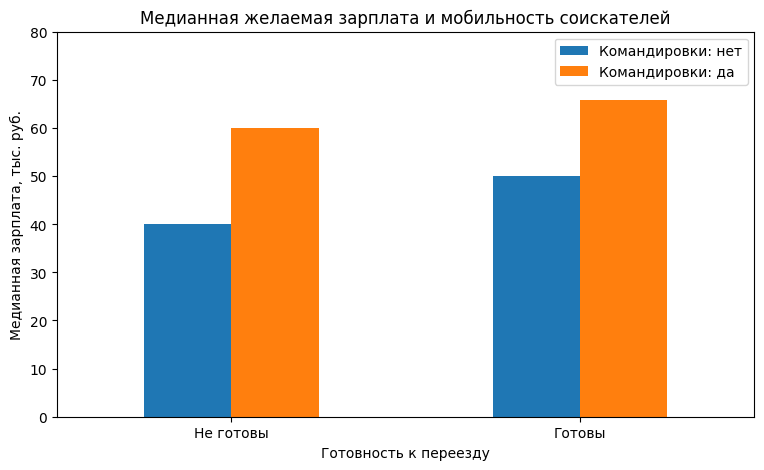

In [18]:
mobility_salary = data.pivot_table(
    values='ЗП (руб)', index='Готовность к переезду',
    columns='Готовность к командировкам', aggfunc='median'
)
plot_mobility = mobility_salary / 1000
plot_mobility.index = ['Не готовы', 'Готовы']
plot_mobility.columns = ['Командировки: нет', 'Командировки: да']

ax = plot_mobility.plot(kind='bar', figsize=(9, 5))
ax.set_title('Медианная желаемая зарплата и мобильность соискателей')
ax.set_xlabel('Готовность к переезду')
ax.set_ylabel('Медианная зарплата, тыс. руб.')
ax.set_yticks(range(0, 81, 10))
ax.xaxis.set_tick_params(rotation=0)
plt.show()

У соискателей, не готовых ни к переезду, ни к командировкам, медианная желаемая зарплата равна 40 тысячам рублей. При готовности только к переезду она составляет 50 тысяч, только к командировкам 60 тысяч рублей. Максимальная медиана у готовых к обоим вариантам: около 65,85 тысячи рублей. В этой выборке готовность к командировкам связана с более заметным различием медиан, чем готовность к переезду.

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

Возраст,14,15,16,17,18,19,20,21,22,23,...,67,68,69,70,71,72,73,76,77,100
Образование,,,,,,,,,,,,,,,,,,,,,
высшее,60000.0,NaN,122582.49,90075.5,30000.0,30000.0,30000.0,35000.0,40000.0,45000.0,...,70000.0,79000.0,112500.0,80000.0,75000.0,75000.0,62500.0,45000.0,90000.0,NaN
неоконченное высшее,NaN,NaN,NaN,80000.0,25000.0,30000.0,31000.0,35000.0,40000.0,40000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
среднее,NaN,10000.0,NaN,44000.0,35000.0,45000.0,29000.0,40000.0,40000.0,35000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
среднее специальное,NaN,2000.0,30000.00,25000.0,25151.0,30000.0,30000.0,30000.0,30000.0,35000.0,...,120000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60000.0


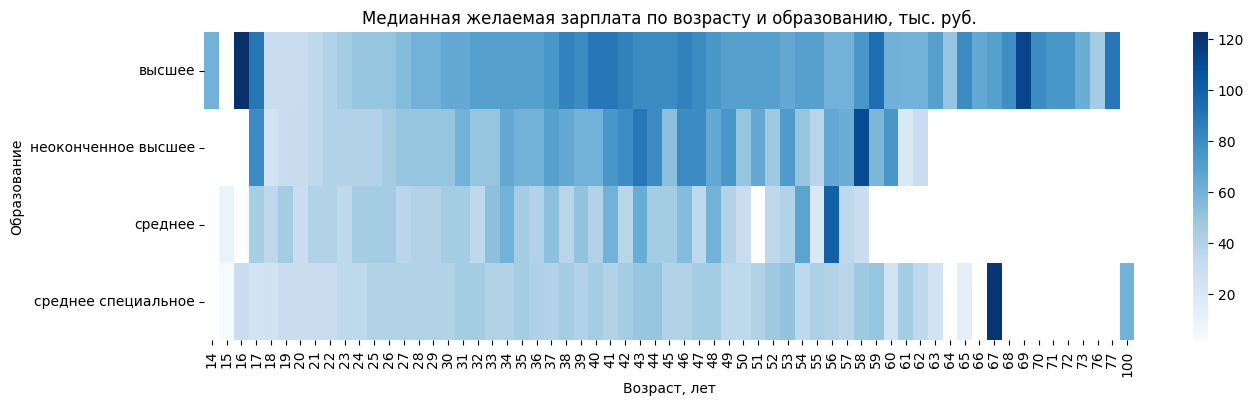

In [19]:
age_education_salary = data.pivot_table(
    values='ЗП (руб)', index='Образование', columns='Возраст', aggfunc='median'
)
display(age_education_salary)

fig, ax = plt.subplots(figsize=(15, 4))
sns.heatmap(data=age_education_salary / 1000, cmap='Blues', ax=ax)
ax.set_title('Медианная желаемая зарплата по возрасту и образованию, тыс. руб.')
ax.set_xlabel('Возраст, лет')
ax.set_ylabel('Образование')
ax.xaxis.set_tick_params(rotation=90)
ax.yaxis.set_tick_params(rotation=0)
plt.show()

Наиболее выраженный рост зарплатных ожиданий от 20 до 40 лет наблюдается у соискателей с высшим образованием. При неоконченном высшем образовании рост слабее, а при среднем и среднем специальном типичные ожидания ниже. К 50 годам медианы во всех четырёх категориях ниже, чем в 40 лет. Белые ячейки обозначают отсутствие наблюдений, а не нулевую зарплату. График сравнивает разных соискателей и не показывает карьеру одного человека во времени.

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

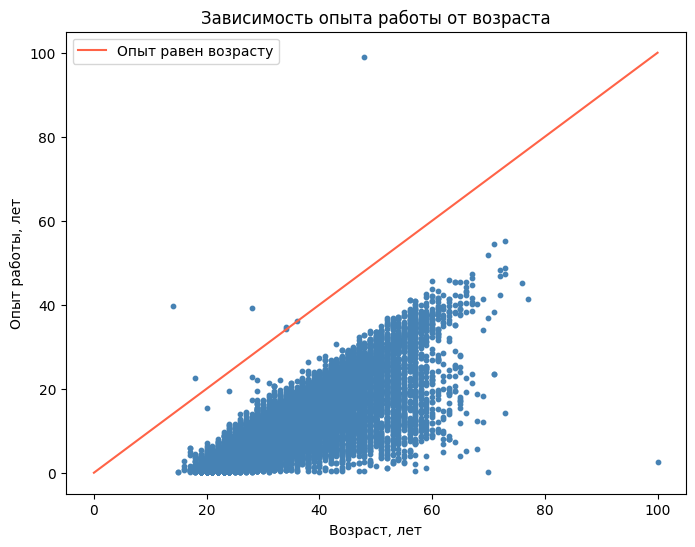

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x=data['Возраст'], y=data['Опыт работы (месяц)'] / 12, s=10, c='steelblue')
ax.plot([0, 100], [0, 100], color='tomato', label='Опыт равен возрасту')
ax.set_title('Зависимость опыта работы от возраста')
ax.set_xlabel('Возраст, лет')
ax.set_ylabel('Опыт работы, лет')
ax.legend()
plt.show()

В основной части выборки опыт увеличивается с возрастом и остаётся меньше него. Есть точки выше прямой: указанный опыт превышает весь возраст человека. Такие резюме содержат противоречивые сведения и подлежат удалению при очистке.

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


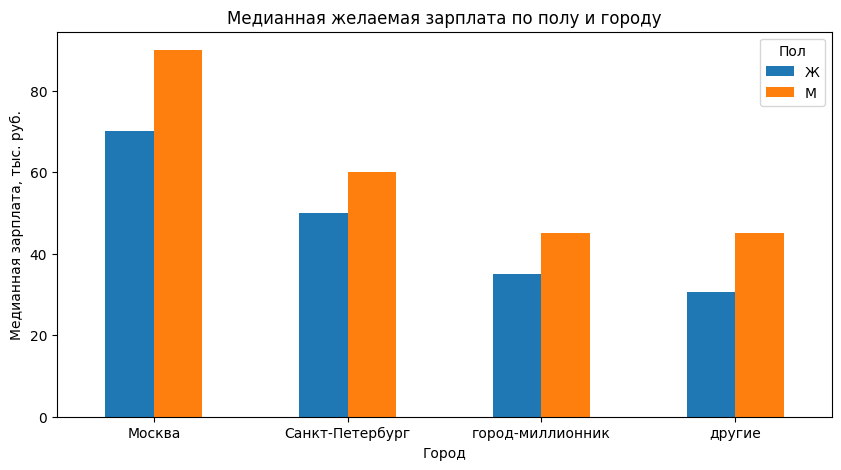

In [21]:
gender_salary = data.pivot_table(
    values='ЗП (руб)', index='Город', columns='Пол', aggfunc='median'
)

ax = (gender_salary / 1000).plot(kind='bar', figsize=(10, 5))
ax.set_title('Медианная желаемая зарплата по полу и городу')
ax.set_xlabel('Город')
ax.set_ylabel('Медианная зарплата, тыс. руб.')
ax.xaxis.set_tick_params(rotation=0)
plt.show()

Во всех четырёх категориях городов медианная желаемая зарплата в мужских резюме выше. В Москве медианы равны 90 тысячам рублей у мужчин и 70 тысячам у женщин, в Санкт-Петербурге 60 и 50 тысячам соответственно. Различие сохраняется внутри городских категорий, однако здесь не учтены профессия и опыт. Это сравнение зарплатных ожиданий, а не фактической оплаты одинакового труда.

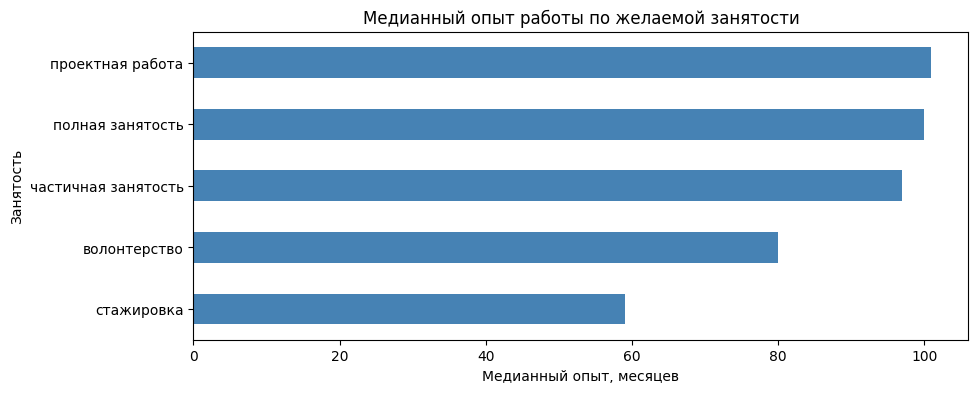

In [22]:
employment_experience = {}
for category in employment_types:
    employment_experience[category] = data.loc[data[category], 'Опыт работы (месяц)'].median()
employment_experience = pd.Series(employment_experience).sort_values()

ax = employment_experience.plot(kind='barh', figsize=(10, 4), color='steelblue')
ax.set_title('Медианный опыт работы по желаемой занятости')
ax.set_xlabel('Медианный опыт, месяцев')
ax.set_ylabel('Занятость')
plt.show()

Самый низкий медианный опыт у соискателей, рассматривающих стажировку: 59 месяцев, самый высокий у рассматривающих проектную работу: 101 месяц. Для полной и частичной занятости медианы близки к проектной работе, для волонтёрства опыт меньше. Категории пересекаются: один человек может выбрать несколько видов занятости.

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [23]:
data = data.drop_duplicates().copy()

2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [24]:
print(data.isnull().sum())

Ищет работу на должность:            0
Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Обновление резюме                    0
Авто                                 0
Образование                          0
Пол                                  0
Возраст                              0
Опыт работы (месяц)                168
Город                                0
Готовность к переезду                0
Готовность к командировкам           0
полная занятость                     0
частичная занятость                  0
проектная работа                     0
волонтерство                         0
стажировка                           0
полный день                          0
сменный график                       0
гибкий график                        0
удаленная работа                     0
вахтовый метод                       0
ЗП (руб)                             0
dtype: int64


3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [25]:
data = data.dropna(subset=[
    'Последнее/нынешнее место работы', 'Последняя/нынешняя должность'
]).copy()
median_experience = data['Опыт работы (месяц)'].median()
data['Опыт работы (месяц)'] = data['Опыт работы (месяц)'].fillna(median_experience)

4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [26]:
salary_mask = (data['ЗП (руб)'] >= 1000) & (data['ЗП (руб)'] <= 1000000)
data = data[salary_mask].copy()

5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [27]:
experience_mask = data['Опыт работы (месяц)'] / 12 <= data['Возраст']
data = data[experience_mask].copy()

6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

,Ищет работу на должность:,Последнее/нынешнее место работы,Последняя/нынешняя должность,Обновление резюме,Авто,Образование,Пол,Возраст,Опыт работы (месяц),Город,...,частичная занятость,проектная работа,волонтерство,стажировка,полный день,сменный график,гибкий график,удаленная работа,вахтовый метод,ЗП (руб)
31137,Менеджер по работе с клиентами,"ООО ""ФёрстКэшКомпани""",Менеджер по работе с клиентами,2019-04-06,Не указано,среднее,М,15,2.0,Санкт-Петербург,...,True,False,False,False,False,True,True,True,False,10000.0
32950,Тестировщик игр,OOO ЖМЫХ,Тестировщик ПО,2019-04-09,Не указано,среднее специальное,М,15,3.0,другие,...,False,False,False,False,True,False,False,False,False,2000.0
33654,Frontend-разработчик,Freelance,Frontend-разработчик,2019-04-19,Не указано,среднее специальное,М,100,30.0,Санкт-Петербург,...,True,True,False,True,True,False,True,True,False,60000.0


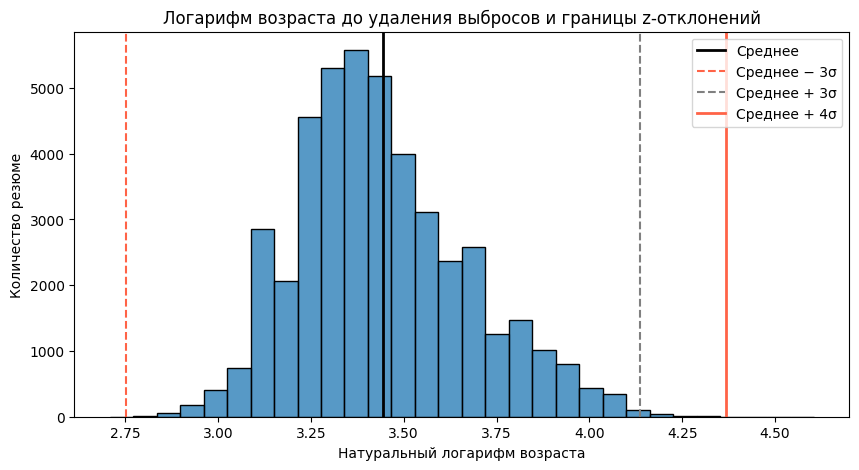

In [28]:
log_age = np.log(data['Возраст'])
mu = log_age.mean()
sigma = log_age.std()
lower_bound = mu - 3 * sigma
upper_three = mu + 3 * sigma
upper_bound = mu + 4 * sigma

age_mask = (log_age < lower_bound) | (log_age > upper_bound)
age_outliers = data[age_mask]
display(age_outliers)
data = data[(log_age >= lower_bound) & (log_age <= upper_bound)].copy()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(x=log_age, bins=30, ax=ax)
ax.axvline(mu, color='black', lw=2, label='Среднее')
ax.axvline(lower_bound, color='tomato', ls='--', label='Среднее − 3σ')
ax.axvline(upper_three, color='gray', ls='--', label='Среднее + 3σ')
ax.axvline(upper_bound, color='tomato', lw=2, label='Среднее + 4σ')
ax.set_title('Логарифм возраста до удаления выбросов и границы z-отклонений')
ax.set_xlabel('Натуральный логарифм возраста')
ax.set_ylabel('Количество резюме')
ax.legend()
plt.show()

Логарифмическое распределение возраста асимметрично вправо. По условию правая граница расширена до четырёх сигм. За границы попали резюме соискателей 15 и 100 лет. Возраст 15 лет сам по себе не доказывает ошибку, но эти строки удалены по заданному статистическому правилу.